## Notebook 1 Conceptos básicos y series de tiempo con Pandas


María Luis a puede empezar a traajar con sus datos. 
Tenemos ONI y precipitación en archivos CSV. ¿Qué contienen y cómo podemos empezar a compararlos?

Antes de abrir jupyter lab y este notebook asegúrate de estar en el directorio notebooks y activar el ambiente de trabajo de conda ``òcenografía``` que se contruye desede el archivo environment.yml.

ype(oni["oni_degC"] > 0.5)Desde la terminal:

cd enso_baja
conda activate oceanografia
jupyter lab

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
type(pd)

module

In [5]:
filename = "../data/oni_mensual_1981_2026.csv"

type(filename)

str

Una variable es un nombre asociado a un objeto

### 2. Leer nuestro primer archivo

In [6]:
oni = pd.read_csv("../data/oni_mensual_1981_2026.csv",
                  parse_dates=["time"])

oni.head()

,time,oni_degC
0,1981-09-01,-0.25
1,1981-10-01,-0.16
2,1981-11-01,-0.13
3,1981-12-01,-0.15
4,1982-01-01,-0.08


¿Qué tipo de variable es oni?

In [7]:
type(oni)

pandas.DataFrame

In [9]:
oni.columns


Index(['time', 'oni_degC'], dtype='str')

In [10]:
oni.shape


(540, 2)

In [13]:
oni.dtypes

time        datetime64[us]
oni_degC           float64
dtype: object

In [12]:
oni.describe()

,time,oni_degC
count,540,540.000000
mean,2004-02-15 08:00:00,0.046185
min,1981-09-01 00:00:00,-1.850000
25%,1992-11-23 12:00:00,-0.552500
50%,2004-02-15 12:00:00,-0.075000
75%,2015-05-08 18:00:00,0.572500
max,2026-08-01 00:00:00,2.750000
std,NaN,0.871231


Reto

¿Cuántos meses hay?
¿Cuál es el ONI máximo y mínimo?

### 3. Seleccionar información

In [14]:
oni["oni_degC"]

0     -0.25
1     -0.16
2     -0.13
3     -0.15
4     -0.08
       ... 
535    0.11
536    0.46
537    0.95
538    1.39
539    1.80
Name: oni_degC, Length: 540, dtype: float64

In [15]:
oni["oni_degC"].mean()

np.float64(0.046185185185185176)

In [16]:
oni.iloc[0]

time        1981-09-01 00:00:00
oni_degC                  -0.25
Name: 0, dtype: object

In [17]:
oni.loc[oni["oni_degC"] > 0.5]

,time,oni_degC
9,1982-06-01,0.66
10,1982-07-01,0.72
11,1982-08-01,0.79
12,1982-09-01,1.07
13,1982-10-01,1.58
...,...,...
511,2024-04-01,1.26
512,2024-05-01,0.82
537,2026-06-01,0.95
538,2026-07-01,1.39


In [18]:
type(oni["oni_degC"] > 0.5)

pandas.Series

### 4. Condicionales

Intriducinmos un if

In [19]:
x = 1.2

if x >= 0.5:
    print("El Niño")
elif x <= -0.5:
    print("La Niña")
else:
    print("Neutral")

El Niño


Vamos a copiar esto 40 veces? Pues no. Hagámos una función:


In [21]:
def enso_phase(oni):
    """Clasifica un valor de ONI de manera simplificada."""
    
    if oni >= 0.5:
        return "El Niño"
    elif oni <= -0.5:
        return "La Niña"
    else:
        return "Neutral"

In [22]:
enso_phase(1.2)

'El Niño'

In [23]:
enso_phase(-0.8)

'La Niña'

Hablar de Nombre, argumento, return, docstring

### 5. Y si queremos hacer esto muchas veces? Ciclos



In [26]:
values = [1.2, -0.8, 0.1]

for value in values:
    print(value, enso_phase(value))

1.2 El Niño
-0.8 La Niña
0.1 Neutral


lista → ciclo → función

en unos 10 minutos y con una razón concreta.


Después puedes mostrar que pandas evita escribir nosotros mismos ese ciclo:

In [28]:
oni["phase"] = oni["oni_degC"].apply(enso_phase)

Esto da pie a una idea importante:

Muchas herramientas científicas ejecutan internamente operaciones repetitivas; no siempre necesitamos escribir un for.


### 6. Segundo CSV: precipitación

In [31]:
rain = pd.read_csv(
    "../data/precipitacion_ensenada_1981_2026.csv",
    parse_dates=["time"]
)

rain.head()

,time,precip_mm
0,1981-09-01,2.0
1,1981-10-01,5.0
2,1981-11-01,68.5
3,1981-12-01,20.0
4,1982-01-01,54.8


In [32]:
rain.info()

<class 'pandas.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   time       540 non-null    datetime64[us]
 1   precip_mm  511 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 8.6 KB


In [33]:
rain.isna().sum()

time          0
precip_mm    29
dtype: int64

Reto:
Encuentra los meses para los que no tenemos precipitación

In [34]:
rain[rain["precip_mm"].isna()]

,time,precip_mm
155,1994-08-01,NaN
169,1995-10-01,NaN
193,1997-10-01,NaN
238,2001-07-01,NaN
253,2002-10-01,NaN
256,2003-01-01,NaN
263,2003-08-01,NaN
310,2007-07-01,NaN
313,2007-10-01,NaN
321,2008-06-01,NaN


Concepto de NaN

### 7. Primera figura

<Axes: xlabel='time'>

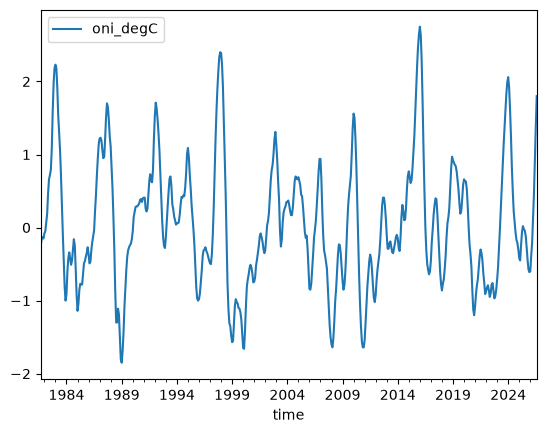

In [37]:
oni.plot(x="time", y="oni_degC")

<Axes: xlabel='time'>

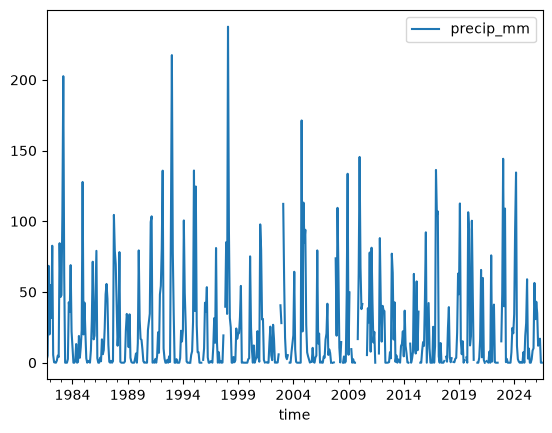

In [38]:
rain.plot(x="time", y="precip_mm")

Y una discusión breve:

¿Tiene sentido comparar directamente estas dos series?

Probablemente percibirán:

ONI varía suavemente;
precipitación es muy intermitente;
precipitación tiene fuerte estacionalidad;
hay datos faltantes.

Perfecto gancho para el proyecto.

### Recapitulación

objeto → DataFrame
selección → []
condición → >, <, ==
decisión → if / elif / else
repetición → for
reutilización → function
datos tabulares → pandas

Ahora necesitamos abrir algo bastante diferente: un campo de SST con tiempo × latitud × longitud.